<a href="https://colab.research.google.com/github/prasxx18-dev/Deep-Learning-Lab/blob/main/Program_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.2779
Epoch 2/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.1695
Epoch 3/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.1428
Epoch 4/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1274
Epoch 5/5
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - loss: 0.1169
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


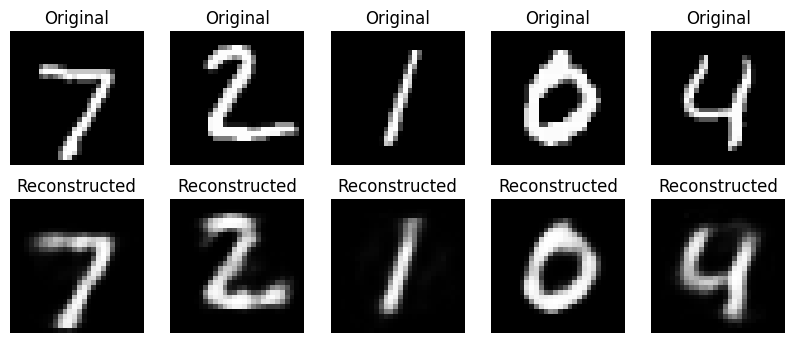

Original size: (10000, 784)
Compressed size: (10000, 32)


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model


(x_train, _), (x_test, _) = tf.keras.datasets.mnist.load_data()


x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)


input_img = layers.Input(shape=(784,))


encoded = layers.Dense(32, activation="relu")(input_img)


decoded = layers.Dense(784, activation="sigmoid")(encoded)


model = Model(input_img, decoded)



model.compile(optimizer="adam", loss="binary_crossentropy")


model.fit(x_train, x_train, epochs=5, batch_size=256)


encoder = Model(input_img, encoded)


encoded_imgs = encoder.predict(x_test)


decoded_imgs = model.predict(x_test)


n = 5

plt.figure(figsize=(10, 4))

for i in range(n):


    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')


    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.show()


print("Original size:", x_test.shape)
print("Compressed size:", encoded_imgs.shape)